In [340]:
import cv2
import sys
import numpy as np
import mediapipe as mp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml

import torch
import torch.nn as nn
import torch.optim as optim




In [341]:
# Configure MediaPipe
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

# Open video
video_path = "data/test_video.mov"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"FPS: {fps}, Frames: {total_frames}")

SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


FPS: 29.998430778235036, Frames: 35366


In [342]:
results_list = []
n = 1000
step = 30

error_n = 0
# Process video
with FaceLandmarker.create_from_options(options) as landmarker:
    frame_idx = 0
    while cap.isOpened() and frame_idx < n*step:
        ret, frame = cap.read()
    
        if not ret:
            break
        
        if frame_idx > total_frames:
            raise IndexError()

        timestamp_ms = int(frame_idx / fps * 1000)

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb
        )

        result = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        if result.face_landmarks:
            h, w, _ = frame.shape

            for landmark in result.face_landmarks[0]:
                x = int(landmark.x * w)
                y = int(landmark.y * h)

                cv2.circle(
                    frame,
                    (x, y),
                    radius=1,
                    color=(0, 255, 0),
                    thickness=-1
                )

        if result.face_blendshapes:
            blendshapes = result.face_blendshapes[0]
        
            blendshape_features = {
                category.category_name: category.score
                for category in blendshapes
            }
            blendshape_features['frame_idx'] = frame_idx
            results_list.append(blendshape_features)
        else:
            print("No face found")
            error_n += 1

        if False:
            plt.clf()
            plt.figure(figsize=(10, 6))
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            plt.title(f"Frame: {frame_idx}")
            plt.axis("off")
            display(plt.gcf())
            clear_output(wait=True)
            
        print(frame_idx)
        frame_idx += step


cap.release()

df = pd.DataFrame(results_list)

print(f'Found object in {len(df)} of {n} samples')

No face found
0
No face found
30
No face found
60
No face found
90
No face found
120
No face found
150
No face found
180
No face found
210
No face found
240
No face found
270
No face found
300
No face found
330
No face found
360
No face found
390
No face found
420
No face found
450
No face found
480
510
540
570
600
630
660
690
720
750
780
810
840
870
900
930
960
990
1020
1050
1080
1110
1140
1170
1200
1230
1260
1290
1320
1350
1380
1410
1440
1470
1500
1530
1560
1590
1620
1650
1680
1710
1740
1770
1800
1830
1860
1890
1920
1950
1980
2010
2040
2070
2100
2130
2160
2190
2220
2250
2280
2310
2340
2370
2400
2430
2460
2490
2520
2550
2580
2610
2640
2670
2700
2730
2760
2790
2820
2850
2880
2910
2940
2970
3000
3030
3060
3090
3120
3150
3180
3210
3240
3270
3300
3330
3360
3390
3420
3450
3480
3510
3540
3570
3600
3630
3660
3690
3720
3750
3780
3810
3840
3870
3900
3930
3960
3990
4020
4050
4080
4110
4140
4170
4200
4230
4260
4290
4320
4350
4380
4410
4440
4470
4500
4530
4560
4590
4620
4650
4680
4710
4740
4770
4

In [343]:
display(df)

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight,frame_idx
0,1.124604e-06,0.000156,0.000080,0.717735,0.584941,0.649571,0.000055,3.871457e-07,7.488090e-07,0.098459,...,0.000730,0.002423,0.002477,0.002837,0.001524,0.000004,0.000009,3.731155e-07,4.131274e-07,510
1,8.408261e-07,0.000222,0.000088,0.710481,0.577716,0.650429,0.000055,2.592653e-07,3.496016e-07,0.125718,...,0.000520,0.013609,0.021432,0.002373,0.003192,0.000008,0.000016,3.443266e-07,3.132655e-07,540
2,8.224631e-07,0.000256,0.000131,0.684458,0.531636,0.542544,0.000044,3.175255e-07,2.533229e-07,0.130221,...,0.000903,0.014565,0.027536,0.002629,0.003476,0.000013,0.000028,3.821105e-07,2.699526e-07,570
3,8.769915e-07,0.000273,0.000144,0.657967,0.540859,0.580363,0.000047,2.766125e-07,3.177211e-07,0.124573,...,0.000685,0.009066,0.012985,0.001984,0.002060,0.000008,0.000013,3.451634e-07,2.862993e-07,600
4,9.452119e-07,0.000236,0.000135,0.693183,0.562313,0.582417,0.000047,2.916461e-07,3.068866e-07,0.114256,...,0.000592,0.006241,0.009466,0.001303,0.001686,0.000006,0.000010,2.779845e-07,2.760215e-07,630
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,3.648270e-07,0.000092,0.000249,0.750065,0.751350,0.329030,0.000013,1.561547e-07,6.503142e-08,0.036571,...,0.001463,0.000311,0.003399,0.000041,0.005502,0.000002,0.000008,2.839245e-07,7.893455e-08,29850
979,3.860614e-07,0.000082,0.000244,0.749940,0.764992,0.332137,0.000014,1.703364e-07,6.769282e-08,0.037313,...,0.001590,0.000306,0.003340,0.000037,0.005193,0.000002,0.000009,2.801349e-07,8.030784e-08,29880
980,3.401062e-07,0.000093,0.000242,0.753036,0.732679,0.325044,0.000011,1.451380e-07,6.055667e-08,0.035420,...,0.001694,0.000202,0.002151,0.000032,0.003668,0.000002,0.000009,2.967263e-07,6.678027e-08,29910
981,3.250231e-07,0.000106,0.000233,0.753975,0.701948,0.335449,0.000010,1.249083e-07,6.413810e-08,0.035300,...,0.001444,0.000185,0.001708,0.000026,0.002628,0.000002,0.000008,2.895385e-07,5.865684e-08,29940


In [344]:
# df.to_csv("video_features.csv", index=False)

In [345]:
X_raw = df.drop(columns=['frame_idx'])

X_scaled = StandardScaler().fit_transform(X_raw)

pca = PCA(n_components=11)
X_pca = pca.fit_transform(X_scaled)

n_clusters = 5

In [346]:
# 1. Definiera Autoencodern
class BlendshapeAutoencoder(nn.Module):
    def __init__(self, input_dim=52, latent_dim=10):
        super().__init__()
        # Encoder: Komprimerar 52 -> 32 -> latent_dim (t.ex. 10)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        # Decoder: Rekonstruerar tillbaka från latent_dim -> 32 -> 51
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# 2. Konvertera din skalade data till PyTorch-tensors
X_tensor = torch.FloatTensor(X_scaled)

# 3. Initiera modell, förlustfunktion och optimerare
input_dim = X_scaled.shape[1]
latent_dim = 2 # Motsvarar n_components=10 som du hade i PCA
model = BlendshapeAutoencoder(input_dim=input_dim, latent_dim=latent_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Träna autoencodern (enkelt träningssteg)
epochs = 100
model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    reconstructions = model(X_tensor)
    loss = criterion(reconstructions, X_tensor)
    loss.backward()
    optimizer.step()

# 5. Extrahera det latenta rummet (ersätter X_pca)
model.eval()
with torch.no_grad():
    X_ae = model.encoder(X_tensor).numpy()

In [347]:
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

In [375]:
max_score = 0
sil_ae_array = np.zeros(11)
inertia_ae_array = np.zeros(11)
for k in range(2, 12):
    # Kör din logik för Autoencoder
    kmeans_ae = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_AE = kmeans_ae.fit_predict(X_ae)
    sil_ae = silhouette_score(X_ae, labels_AE)
    
    if sil_ae > max_score:
        max_score = sil_ae
        n_clusters = k
    
    sil_ae_array[k-1] = sil_ae
    inertia_ae_array[k-1] = kmeans_ae.inertia_

    # # Kör din logik för PCA
    # kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
    # labels_PCA = kmeans_pca.fit_predict(X_pca)
    # sil_pca = silhouette_score(X_pca, labels_PCA)

    # print(f"--- Antal kluster (k) = {k} ---")
    # print(f"Autoencoder -> Inertia: {kmeans_ae.inertia_:.2f} | Silhouette: {sil_ae:.3f}")
    # print(f"PCA         -> Inertia: {kmeans_pca.inertia_:.2f} | Silhouette: {sil_pca:.3f}\n")


print(f'Clusterss proposed: {n_clusters}')

# Change clusters based on elbow plot
n_clusters = 6
print(f'Clusters used: {n_clusters}')

kmeans = KMeans(n_clusters=n_clusters,random_state=SEED, n_init=10)

labels_AE = kmeans.fit_predict(X_ae)
labels_PCA = kmeans.fit_predict(X_pca)
labels_tsne = kmeans.fit_predict(X_tsne)

Clusterss proposed: 3
Clusters used: 6


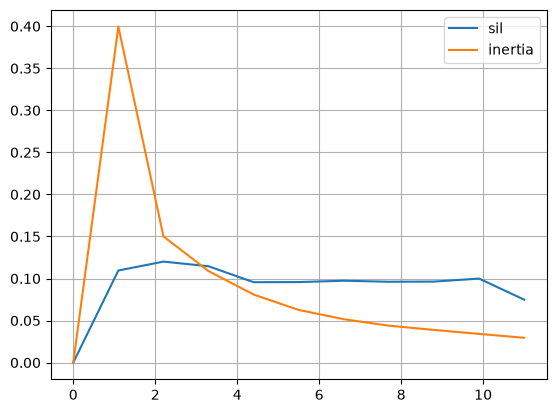

In [376]:
x = np.linspace(0,11,11)
plt.plot(x, sil_ae_array/np.sum(sil_ae_array), label="sil")
plt.plot(x, inertia_ae_array/np.sum(inertia_ae_array), label="inertia")
plt.legend()
plt.grid()
plt.show()

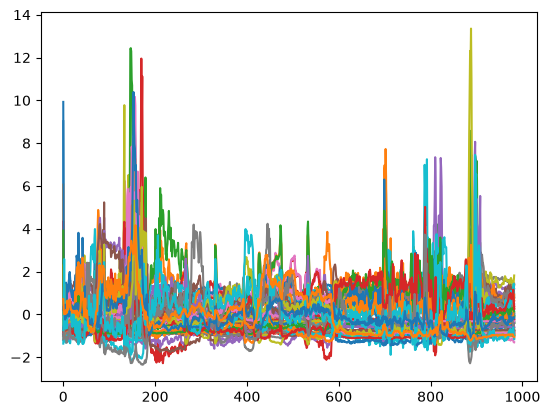

In [377]:
plt.plot(X_scaled)
plt.show()

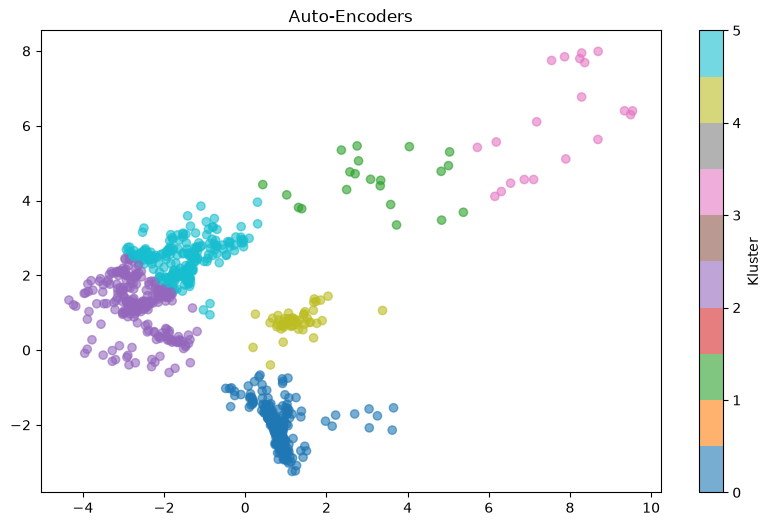

In [378]:
plt.figure(figsize=(10, 6))
plt.scatter(X_ae[:, 0], X_ae[:, 1], c=labels_AE, cmap='tab10', alpha=0.6)
plt.title("Auto-Encoders")
plt.colorbar(label='Kluster')
plt.show()

In [379]:
# Skapa din dataframe med latenta dimensioner, kluster och frame_idx
df_latent = pd.DataFrame(X_ae[:, :2], columns=['Latent 1', 'Latent 2'])
df_latent['Cluster'] = labels_AE.astype(str)  # Konvertera till sträng för diskreta färger
df_latent['frame_idx'] = df['frame_idx'].values  # För att kunna spåra bildrutan

# Skapa den interaktiva plotten med samma färgpalett ('tab10') som i Matplotlib
fig = px.scatter(
    df_latent,
    x='Latent 1',
    y='Latent 2',
    color='Cluster',
    hover_data=['frame_idx'],
    title='Auto-Encoders (Latent Space)',
    opacity=0.6 # Motsvarar alpha=0.6 i din plt.scatter
)

# Justera layouten för att efterlikna en ren stil
fig.update_layout(
    xaxis_title='Latent 1',
    yaxis_title='Latent 2',
    template='plotly_white'
)

fig.show()

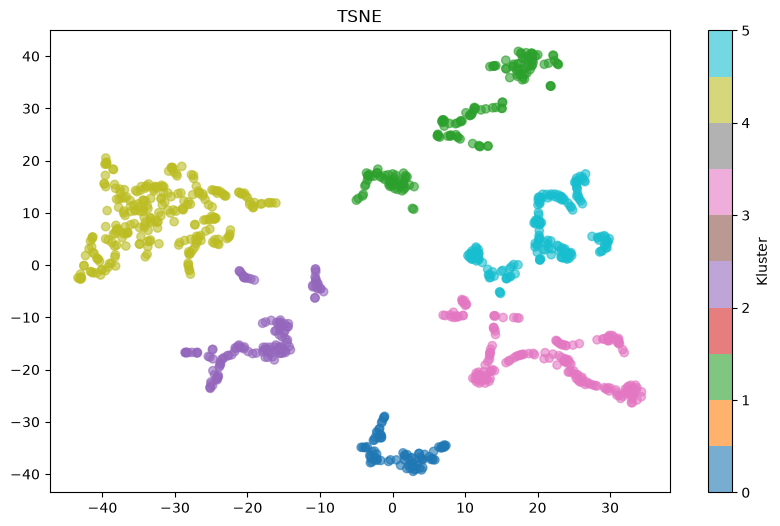

In [380]:
plt.figure(figsize=(10, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_tsne, cmap='tab10', alpha=0.6)
plt.title("TSNE")
plt.colorbar(label='Kluster')
plt.show()

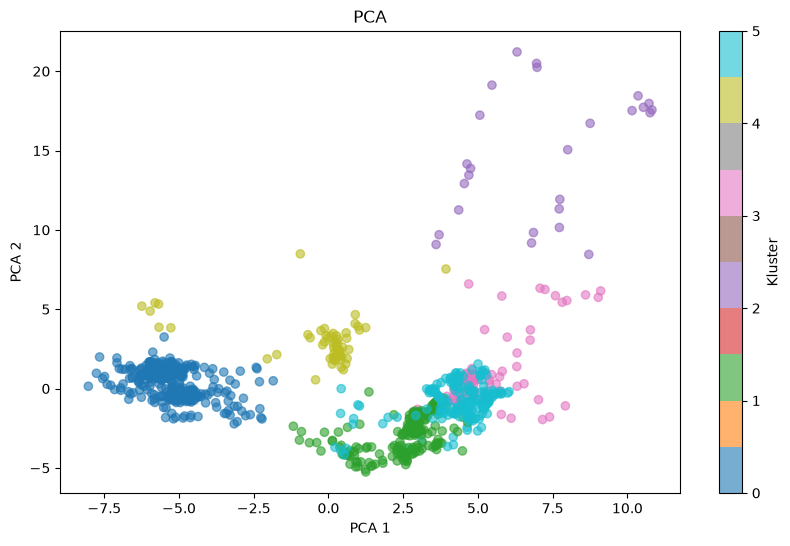

In [381]:
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_PCA, cmap='tab10', alpha=0.6)
plt.title("PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label='Kluster')
plt.show()

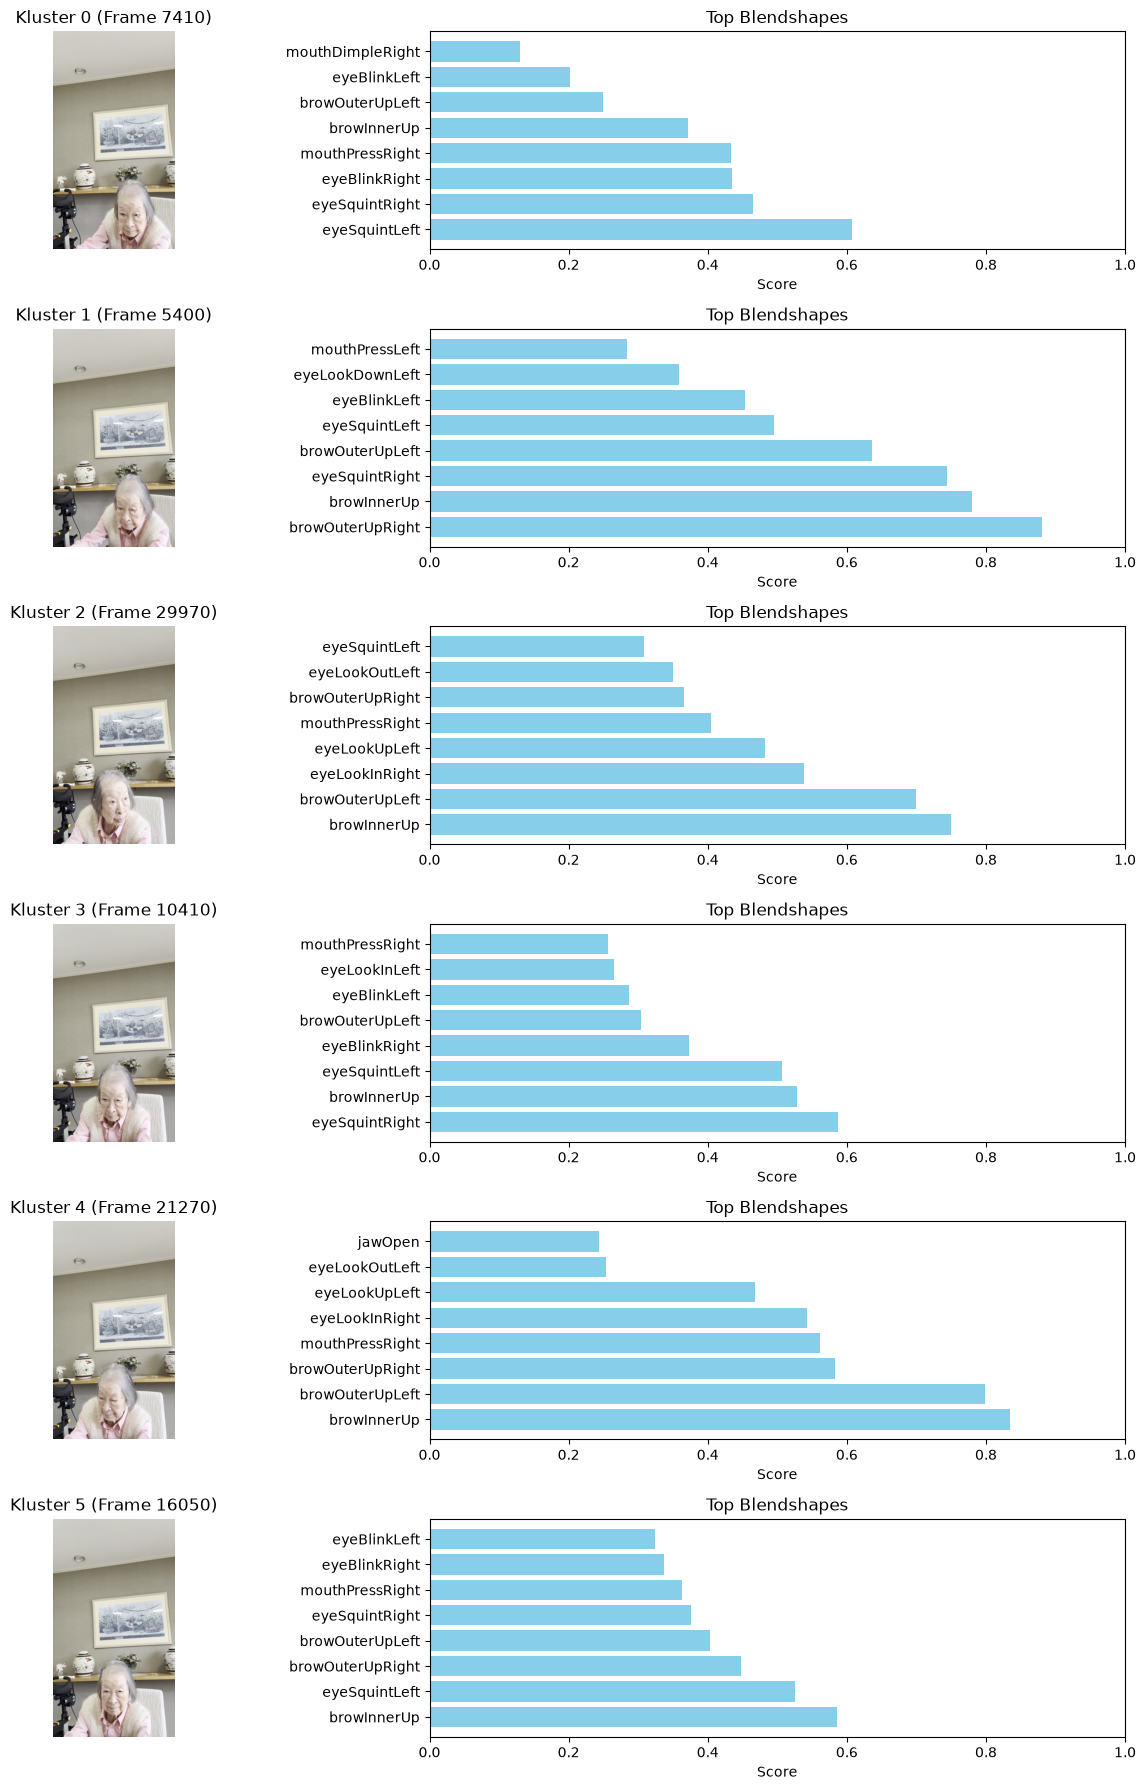

In [ ]:
# Antal kluster du har (samma som n_clusters i din KMeans)
n_clusters = len(np.unique(labels_tsne))

# Hitta ursprungliga kolumnnamn för blendshapes (alla kolumner förutom 'frame_idx')
blendshape_cols = [col for col in df.columns if col != 'frame_idx']

plt.figure(figsize=(14, 3 * n_clusters))

for cluster_id in range(n_clusters):
    # Hitta alla index i vår DataFrame som tillhör detta kluster
    cluster_mask = (labels_tsne == cluster_id)
    cluster_indices = np.where(cluster_mask)[0]
    
    if len(cluster_indices) == 0:
        continue
        
    # Hitta punkten som ligger närmast klustrets centroid i PCA-rymden
    cluster = X_tsne[cluster_mask]
    cluster_centroid = np.mean(cluster, axis=0)
    distances = np.linalg.norm(cluster - cluster_centroid, axis=1)
    best_idx_in_cluster = cluster_indices[np.argmin(distances)]
    
    # Hämta motsvarande bildrutans index och läs in bilden från videon
    target_frame_idx = int(df.iloc[best_idx_in_cluster]['frame_idx'])
    
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret:
        continue
        
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Hämta de högsta blendshapes för detta kluster (medelvärde eller den bästa bilden)
    bs_values = df.iloc[best_idx_in_cluster][blendshape_cols].astype(float)
    top_features = bs_values.nlargest(8)  # Visa de 8 starkaste muskelrörelserna

    # --- Rita subplots: Bild till vänster, Stapeldiagram till höger ---
    
    # 1. Bilden
    plt.subplot(n_clusters, 2, cluster_id * 2 + 1)
    plt.imshow(frame_rgb)
    plt.title(f"Kluster {cluster_id} (Frame {target_frame_idx})")
    plt.axis('off')
    
    # 2. Stapeldiagrammet (Bars)
    plt.subplot(n_clusters, 2, cluster_id * 2 + 2)
    y_pos = np.arange(len(top_features))
    plt.barh(y_pos, top_features.values, align='center', color='skyblue')
    plt.yticks(y_pos, top_features.index)
    plt.xlabel("Score")
    plt.title("Top Blendshapes")
    plt.xlim(0, 1.0)

plt.tight_layout()
plt.show()

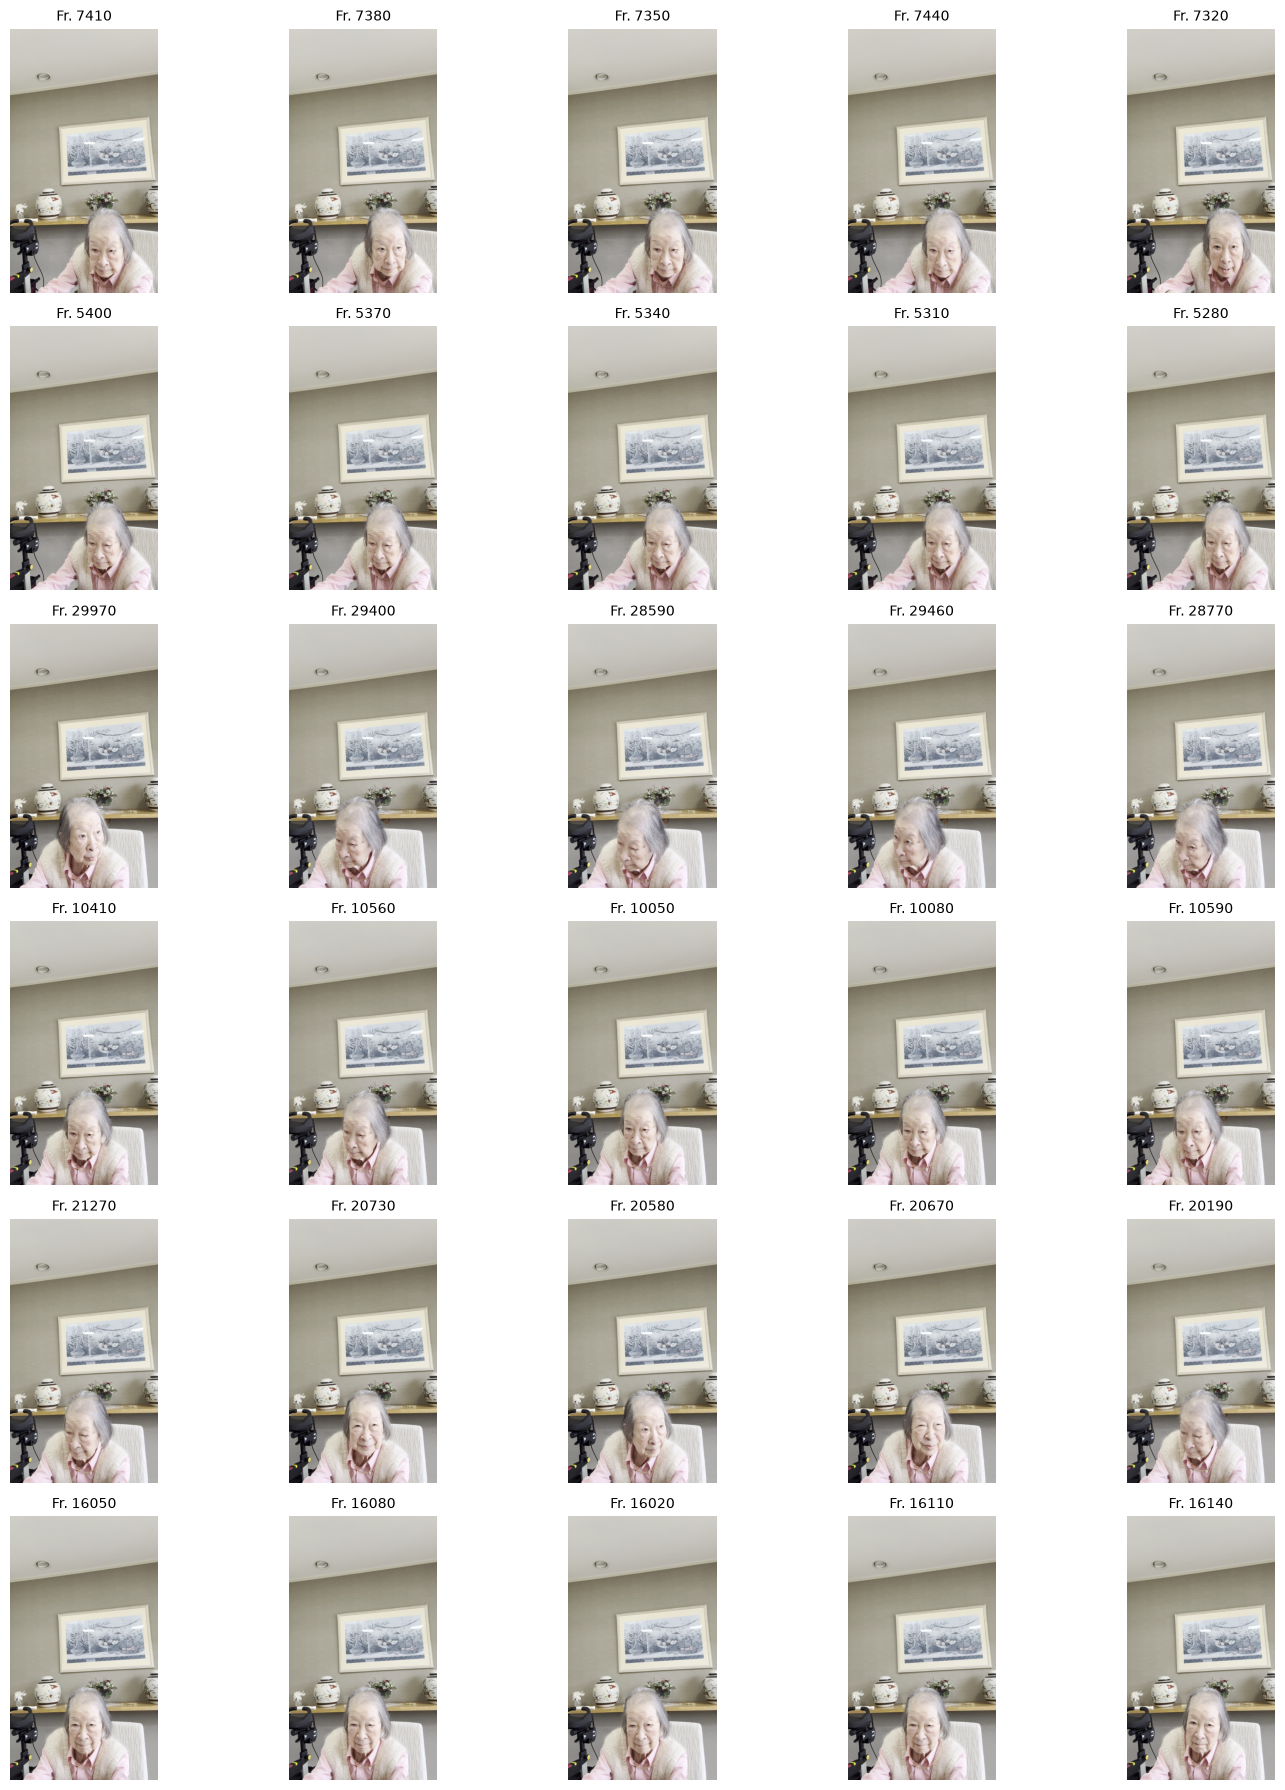

In [386]:
# Bestäm hur många bilder du vill visa per kluster
X_bästa = 5

n_clusters = len(np.unique(labels_tsne))

# Sätt upp en figur där varje kluster får en egen rad med större bilder
plt.figure(figsize=(3 * X_bästa, 3 * n_clusters))

for cluster_id in range(n_clusters):
    cluster_mask = (labels_tsne == cluster_id)
    cluster_indices = np.where(cluster_mask)[0]
    
    if len(cluster_indices) == 0:
        continue
        
    # Beräkna avstånd till centroid i det latenta rummet
    cluster_latent = X_tsne[cluster_mask]
    cluster_centroid = np.mean(cluster_latent, axis=0)
    distances = np.linalg.norm(cluster_latent - cluster_centroid, axis=1)
    
    # Sortera efter lägst avstånd (närmast centroiden)
    sorted_local_indices = np.argsort(distances)
    best_local_indices = sorted_local_indices[:X_bästa]
    best_global_indices = cluster_indices[best_local_indices]
    
    # Plotta bilderna efter varandra på raden för detta kluster
    for i, global_idx in enumerate(best_global_indices):
        target_frame_idx = int(df.iloc[global_idx]['frame_idx'])
        
        cap = cv2.VideoCapture(video_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_idx)
        ret, frame = cap.read()
        cap.release()
        
        if not ret:
            continue
            
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        # Skapa subplot för denna bild
        plt.subplot(n_clusters, X_bästa, cluster_id * X_bästa + i + 1)
        plt.imshow(frame_rgb)
        
        # Sätt titel endast på första bilden i raden för att hålla det rent, eller på alla
        if i == 0:
            plt.ylabel(f"Kluster {cluster_id}", fontsize=12, fontweight='bold')
        
        plt.title(f"Fr. {target_frame_idx}", fontsize=10)
        plt.axis('off')

plt.tight_layout()
plt.show()